In [1]:
import pandas as pd

CAMINHO = "../data/raw/"

pedidos    = pd.read_csv(CAMINHO + "olist_orders_dataset.csv")
avaliacoes = pd.read_csv(CAMINHO + "olist_order_reviews_dataset.csv")
itens      = pd.read_csv(CAMINHO + "olist_order_items_dataset.csv")
clientes   = pd.read_csv(CAMINHO + "olist_customers_dataset.csv")
produtos   = pd.read_csv(CAMINHO + "olist_products_dataset.csv")
vendedores = pd.read_csv(CAMINHO + "olist_sellers_dataset.csv")
pagamentos = pd.read_csv(CAMINHO + "olist_order_payments_dataset.csv")

for nome, df in [("pedidos", pedidos), ("avaliacoes", avaliacoes), ("itens", itens),
                 ("clientes", clientes), ("produtos", produtos),
                 ("vendedores", vendedores), ("pagamentos", pagamentos)]:
    print(f"{nome:12} {df.shape[0]:>7} linhas  {df.shape[1]:>2} colunas")

pedidos        99441 linhas   8 colunas
avaliacoes     99224 linhas   7 colunas
itens         112650 linhas   7 colunas
clientes       99441 linhas   5 colunas
produtos       32951 linhas   9 colunas
vendedores      3095 linhas   4 colunas
pagamentos    103886 linhas   5 colunas


                qtd     %
review_score             
1             11424  11.5
2              3151   3.2
3              8179   8.2
4             19142  19.3
5             57328  57.8


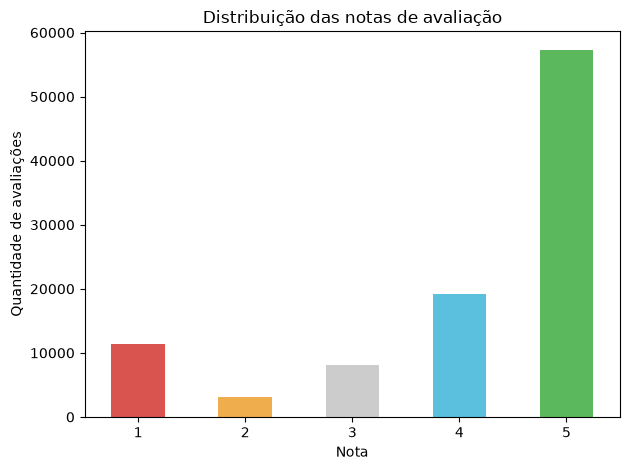

In [2]:
import matplotlib.pyplot as plt

distribuicao = avaliacoes["review_score"].value_counts().sort_index()
percentual = (distribuicao / distribuicao.sum() * 100).round(1)

print(pd.DataFrame({"qtd": distribuicao, "%": percentual}))

ax = distribuicao.plot(kind="bar", color=["#d9534f", "#f0ad4e", "#cccccc", "#5bc0de", "#5cb85c"])
ax.set_title("Distribuição das notas de avaliação")
ax.set_xlabel("Nota")
ax.set_ylabel("Quantidade de avaliações")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../reports/figures/distribuicao_notas.png", dpi=120)
plt.show()

In [3]:
# Uma avaliação por pedido: fica a resposta mais recente
avaliacoes["review_answer_timestamp"] = pd.to_datetime(avaliacoes["review_answer_timestamp"])
avaliacoes_unicas = (avaliacoes
                     .sort_values("review_answer_timestamp")
                     .drop_duplicates("order_id", keep="last"))

# Converte as colunas de data dos pedidos
for col in ["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]:
    pedidos[col] = pd.to_datetime(pedidos[col])

# Junta pedidos + avaliação e cria o alvo
base = pedidos.merge(avaliacoes_unicas[["order_id", "review_score"]], on="order_id")
base["negativa"] = (base["review_score"] <= 2).astype(int)

print("pedidos com avaliação:", len(base))
print("taxa de avaliação negativa:", round(base["negativa"].mean() * 100, 1), "%")

pedidos com avaliação: 98673
taxa de avaliação negativa: 14.7 %


In [4]:
# Só pedidos entregues (os outros não têm data de entrega)
entregues = base[(base["order_status"] == "delivered") & base["order_delivered_customer_date"].notna()].copy()

# Atraso = data real de entrega - data prometida (em dias)
entregues["dias_atraso"] = (entregues["order_delivered_customer_date"]
                            - entregues["order_estimated_delivery_date"]).dt.days
entregues["atrasado"] = entregues["dias_atraso"] > 0

resumo = entregues.groupby("atrasado")["negativa"].agg(pedidos="count", taxa_negativa="mean")
resumo["taxa_negativa"] = (resumo["taxa_negativa"] * 100).round(1)
print(resumo)

          pedidos  taxa_negativa
atrasado                        
False       89443            9.3
True         6381           62.4


In [5]:
# Resume os itens por pedido (grão: 1 linha por pedido)
itens_por_pedido = (itens.groupby("order_id")
                    .agg(n_itens=("order_item_id", "count"),
                         n_vendedores=("seller_id", "nunique"),
                         valor_total=("price", "sum"),
                         frete_total=("freight_value", "sum"))
                    .reset_index())

entregues = entregues.merge(itens_por_pedido, on="order_id")

# Tempo total de entrega (da compra até a chegada)
entregues["dias_entrega"] = (entregues["order_delivered_customer_date"]
                             - entregues["order_purchase_timestamp"]).dt.days


def taxa_por(coluna):
    t = entregues.groupby(coluna, observed=True)["negativa"].agg(pedidos="count", taxa_negativa="mean")
    t["taxa_negativa"] = (t["taxa_negativa"] * 100).round(1)
    return t


entregues["faixa_itens"] = pd.cut(entregues["n_itens"], [0, 1, 2, 100], labels=["1", "2", "3+"])
entregues["faixa_vendedores"] = entregues["n_vendedores"].clip(upper=2).map({1: "1", 2: "2+"})
entregues["faixa_entrega"] = pd.cut(entregues["dias_entrega"], [-1, 7, 14, 21, 30, 1000],
                                    labels=["até 7", "8-14", "15-21", "22-30", "30+"])

print(taxa_por("faixa_itens"), "\n")
print(taxa_por("faixa_vendedores"), "\n")
print(taxa_por("faixa_entrega"))

             pedidos  taxa_negativa
faixa_itens                        
1              86296           11.3
2               7319           25.4
3+              2209           31.2 

                  pedidos  taxa_negativa
faixa_vendedores                        
1                   94563           12.3
2+                   1261           47.2 

               pedidos  taxa_negativa
faixa_entrega                        
até 7            33539            7.6
8-14             36190            9.3
15-21            15264           12.5
22-30             6824           27.2
30+               4007           65.3


In [6]:
# Uma avaliação por pedido, junto com o número de vendedores
negativas = (avaliacoes_unicas
             .merge(itens_por_pedido[["order_id", "n_vendedores"]], on="order_id")
             .query("review_score <= 2"))

padrao = r"(?i)falt|apenas|só recebi|so recebi|somente|não recebi|nao recebi|incomplet|um dos"
negativas["fala_de_falta"] = negativas["review_comment_message"].str.contains(padrao, na=False)

comentadas = negativas[negativas["review_comment_message"].notna()]
print(comentadas.groupby(comentadas["n_vendedores"] >= 2)["fala_de_falta"].mean().mul(100).round(1))

# Alguns exemplos de comentários
print(comentadas[comentadas["n_vendedores"] >= 2]["review_comment_message"].head(5).tolist())

n_vendedores
False    28.0
True     68.0
Name: fala_de_falta, dtype: float64
['faltou a almofada cocozinho, na nota consta o produto, mas o produto NÃO foi entregue', 'Prazo não foi cumprido ... até hoje não chegou :( primeira vez que tenho problema com entrega.', 'Somente recebi as duas cortinas que faltaram, depois de abrir uma reckamacao junto ao Reclame Aqui. Nao indico e nao volto a comprar ', 'Fiz a compra de 2produtos sendo um o sanitário ecopatio entregue no dia 04/02/17 podem o segundo produto que é o bebedouro não foi entregue como ficará está falta aguardo retorno !!', 'Adquiri 2 Suportes e apenas recebi 1 e foi faturado os dois, porem chegou apenas o Transbike para bicicletas Aro 29. O Suporte De Parede Para Sua Bicicleta Atrio não chegou.']


## Principais achados da exploração

- **14,7%** das avaliações são negativas (notas 1 e 2). A base é desbalanceada, então acurácia não é uma boa métrica.
- **Atraso** é o fator mais forte: pedidos atrasados têm 62% de avaliações negativas, contra 9% dos pedidos no prazo (6,7x).
- Mas **68% das avaliações negativas acontecem em pedidos entregues no prazo**: o atraso sozinho não explica o problema.
- Pedidos com **2+ vendedores** têm 47% de avaliações negativas. Pelos comentários, a causa principal é a **entrega parcial**.
- Quanto **maior o tempo total de entrega** e o **número de itens**, maior a chance de avaliação negativa.